# Plotting part 2

This notebook covers both plotting from dataframes and indexing and slicing dataframes.

In [1]:
# WE will start with our imports using the aliases for both
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
# Step 1 read in the data
data = pd.read_csv("data/gapminder_gdp_oceania.csv", index_col = "country") # We want to use the country as the index again
data

,gdpPercap_1952,gdpPercap_1957,gdpPercap_1962,gdpPercap_1967,gdpPercap_1972,gdpPercap_1977,gdpPercap_1982,gdpPercap_1987,gdpPercap_1992,gdpPercap_1997,gdpPercap_2002,gdpPercap_2007
country,,,,,,,,,,,,
Australia,10039.59564,10949.64959,12217.22686,14526.12465,16788.62948,18334.19751,19477.00928,21888.88903,23424.76683,26997.93657,30687.75473,34435.36744
New Zealand,10556.57566,12247.39532,13175.67800,14463.91893,16046.03728,16233.71770,17632.41040,19007.19129,18363.32494,21050.41377,23189.80135,25185.00911


In [4]:
# chaining together attributes and methods
# note: this is a series of calls made in a single line, so let's break it down
# The dataframe, data, has an attribute columns
# columns is an array and the array has an attribute str (access the values as strings)
# strings have a method called replace and replace takes the first argument and replaces it with the second in a string
# So we have taken a dataframe and returned an array with an updated set of strings
# It has not changed the dataframe, but made a new variable with this array
years = data.columns.str.replace("gdpPercap_", "")
years = data.columns.str.replace("gdpPercap_", "")
print(years)

Index(['1952', '1957', '1962', '1967', '1972', '1977', '1982', '1987', '1992',
       '1997', '2002', '2007'],
      dtype='object')


In [5]:
# We want the years as integers so that matplotlib can understand them to include in the ticks
# We can change the data type with the .astype() method and set the numbers as integers
# NOTE: this would not work if we still had country as one of the columns as it can't be changed to an integer
years = years.astype(int)
print(years)

Index([1952, 1957, 1962, 1967, 1972, 1977, 1982, 1987, 1992, 1997, 2002, 2007], dtype='int32')


In [6]:
# Setting the dataframe columns to the new integer format of the years
data.columns = years
data

,1952,1957,1962,1967,1972,1977,1982,1987,1992,1997,2002,2007
country,,,,,,,,,,,,
Australia,10039.59564,10949.64959,12217.22686,14526.12465,16788.62948,18334.19751,19477.00928,21888.88903,23424.76683,26997.93657,30687.75473,34435.36744
New Zealand,10556.57566,12247.39532,13175.67800,14463.91893,16046.03728,16233.71770,17632.41040,19007.19129,18363.32494,21050.41377,23189.80135,25185.00911


<Axes: >

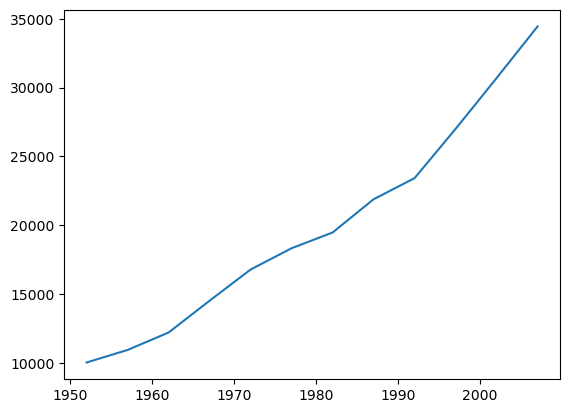

In [7]:
# Dataframes use matplotlib to use their plot method
data.loc["Australia"].plot()

In [8]:
# We are going to use the transpose attribute of the dataframe
# Transposed data is like rotating it 90 degrees, the indexes become the columns and the columns become indexes
data.T

country,Australia,New Zealand
1952,10039.59564,10556.57566
1957,10949.64959,12247.39532
1962,12217.22686,13175.67800
1967,14526.12465,14463.91893
1972,16788.62948,16046.03728
1977,18334.19751,16233.71770
1982,19477.00928,17632.41040
1987,21888.88903,19007.19129
1992,23424.76683,18363.32494
1997,26997.93657,21050.41377


Text(0, 0.5, 'GDP per capita')

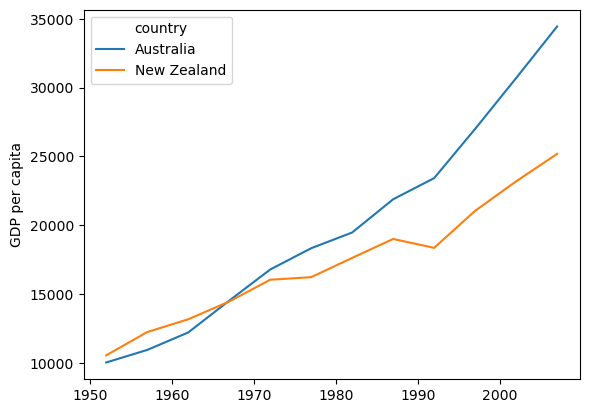

In [9]:
# This time we transpose the data (rotate by 90 degrees) and plot the whole dataframe
# This plot will take each column as its own dataset and label it with the column name (now the country names)
data.T.plot()
plt.ylabel("GDP per capita")

Text(0, 0.5, 'GDP per capita')

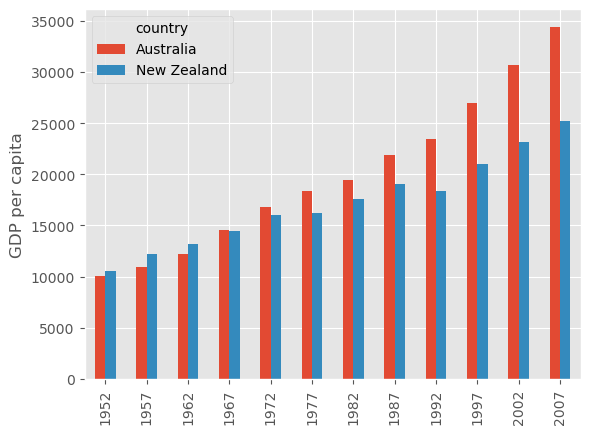

In [10]:
# trying out different styles of plots
# matplotlib is very versatile and has some predetermined styles in built as well
# for those who are used to R or work in a field where R is common you might want your plots to look the same
# ggplot is the most popular R plotting library and matplotlib can replicate its style
plt.style.use("ggplot") # We provide a string and the method knows what to do with it
data.T.plot(kind = "bar") # We can make use of the kind argument in the plot method to change the chart type
plt.ylabel("GDP per capita")

# Indexing in pandas

In [12]:
# reading in our data and adding the country as the index again
data_eu = pd.read_csv("data/gapminder_gdp_europe.csv", index_col = "country")
# The pandas documentation has other file options
# if the type this and press tab you can see all the different types of files pandas can read
# pd.read
data_eu.head()

,gdpPercap_1952,gdpPercap_1957,gdpPercap_1962,gdpPercap_1967,gdpPercap_1972,gdpPercap_1977,gdpPercap_1982,gdpPercap_1987,gdpPercap_1992,gdpPercap_1997,gdpPercap_2002,gdpPercap_2007
country,,,,,,,,,,,,
Albania,1601.056136,1942.284244,2312.888958,2760.196931,3313.422188,3533.003910,3630.880722,3738.932735,2497.437901,3193.054604,4604.211737,5937.029526
Austria,6137.076492,8842.598030,10750.721110,12834.602400,16661.625600,19749.422300,21597.083620,23687.826070,27042.018680,29095.920660,32417.607690,36126.492700
Belgium,8343.105127,9714.960623,10991.206760,13149.041190,16672.143560,19117.974480,20979.845890,22525.563080,25575.570690,27561.196630,30485.883750,33692.605080
Bosnia and Herzegovina,973.533195,1353.989176,1709.683679,2172.352423,2860.169750,3528.481305,4126.613157,4314.114757,2546.781445,4766.355904,6018.975239,7446.298803
Bulgaria,2444.286648,3008.670727,4254.337839,5577.002800,6597.494398,7612.240438,8224.191647,8239.854824,6302.623438,5970.388760,7696.777725,10680.792820


In [13]:
# Pandas has two ways to index the data, iloc and loc
# Because there are two ways we first use a "." as it is a pandas specific form of indexing
# Numeric/positional indexing
# Getting the first value in the table, treat it like a coordinate system
data_eu.iloc[0, 0] # The tables are 2D, so they work on a coordinate like system to access the values

1601.056136

In [14]:
# Another way to get the first value
data_eu.loc["Albania", "gdpPercap_1952"]

1601.056136

In [15]:
# slicinging in dataframes. We can use the slicing method like with strings and lists
# Getting all columns for germany
data_eu.loc["Germany", : ] 
# Having an empty colon (":") means python fills in 0 on the left and the length of the dataframe on the right

gdpPercap_1952     7144.114393
gdpPercap_1957    10187.826650
gdpPercap_1962    12902.462910
gdpPercap_1967    14745.625610
gdpPercap_1972    18016.180270
gdpPercap_1977    20512.921230
gdpPercap_1982    22031.532740
gdpPercap_1987    24639.185660
gdpPercap_1992    26505.303170
gdpPercap_1997    27788.884160
gdpPercap_2002    30035.801980
gdpPercap_2007    32170.374420
Name: Germany, dtype: float64

In [19]:
# All rows for the year 2007
data_eu.loc[ : , "gdpPercap_2007"]

country
Albania                    5937.029526
Austria                   36126.492700
Belgium                   33692.605080
Bosnia and Herzegovina     7446.298803
Bulgaria                  10680.792820
Croatia                   14619.222720
Czech Republic            22833.308510
Denmark                   35278.418740
Finland                   33207.084400
France                    30470.016700
Germany                   32170.374420
Greece                    27538.411880
Hungary                   18008.944440
Iceland                   36180.789190
Ireland                   40675.996350
Italy                     28569.719700
Montenegro                 9253.896111
Netherlands               36797.933320
Norway                    49357.190170
Poland                    15389.924680
Portugal                  20509.647770
Romania                   10808.475610
Serbia                     9786.534714
Slovak Republic           18678.314350
Slovenia                  25768.257590
Spain            

In [20]:
# The first 2 rows and 2nd and 3rd columns
data_eu.iloc[ :2, 1:3]

,gdpPercap_1957,gdpPercap_1962
country,,
Albania,1942.284244,2312.888958
Austria,8842.598030,10750.721110


In [21]:
# You might notice that the last two cells outputs look different
# That is because the first is a single column and that is a series object
# The second has multiplt columns and is a dataframe (though a subset of our original)
# comparing the object types
print(type(data_eu.iloc[ :2, 1:3]))
print(type(data_eu.loc[ : , "gdpPercap_2007"]))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.series.Series'>


In [30]:
# Ranges and slicing also works with .loc and the text names of columns and rows
# more slicing using the names of indexes and columns and applying a method (max) to the resulting dataframe
data_eu.loc["Italy":"Poland", "gdpPercap_1962":"gdpPercap_1977"].max()

gdpPercap_1962    13450.40151
gdpPercap_1967    16361.87647
gdpPercap_1972    18965.05551
gdpPercap_1977    23311.34939
dtype: float64

In [29]:
# If the indexing does not succeed you will get back an empty series, it is more of a search than a check
data.loc["Italy":"Poland", "gdpPercap_1962":"gpdPercap_1977"].max()

Series([], dtype: float64)

In [32]:
# Getting back the index value of the maximum per column
data_eu.loc["Italy":"Poland", "gdpPercap_1962":"gdpPercap_1977"].idxmax()

gdpPercap_1962    Norway
gdpPercap_1967    Norway
gdpPercap_1972    Norway
gdpPercap_1977    Norway
dtype: object

In [33]:
data_eu.loc["Germany":"Ukraine", "gdpPercap_1957":"gdpPercap_1982"].min()

gdpPercap_1957    2218.754257
gdpPercap_1962    2322.869908
gdpPercap_1967    2826.356387
gdpPercap_1972    3450.696380
gdpPercap_1977    4269.122326
gdpPercap_1982    4241.356344
dtype: float64

In [34]:
# Making a subset of the original data and filtering it 
subset = data_eu.loc["Italy":"Poland", "gdpPercap_1962":"gdpPercap_1972"]
# Which values are greater than 10,000?
print("Where are values large?", subset > 10000)
# Because this is an assertion we get back True or False for each cell that it checks

Where are values large?              gdpPercap_1962  gdpPercap_1967  gdpPercap_1972
country                                                    
Italy                 False            True            True
Montenegro            False           False           False
Netherlands            True            True            True
Norway                 True            True            True
Poland                False           False           False


In [ ]:
# Notice that they start with a capital
True # This is a recognised value by Python, it is called a boolean
# We will cover this in a later notebook

In [35]:
# Creating a mask to hide certain values
mask = subset > 10000
print(subset[mask])

             gdpPercap_1962  gdpPercap_1967  gdpPercap_1972
country                                                    
Italy                   NaN     10022.40131     12269.27378
Montenegro              NaN             NaN             NaN
Netherlands     12790.84956     15363.25136     18794.74567
Norway          13450.40151     16361.87647     18965.05551
Poland                  NaN             NaN             NaN


In [36]:
# Let's examine the stats
print(subset[mask].describe())
# The count actually provides the count of values, not rows

       gdpPercap_1962  gdpPercap_1967  gdpPercap_1972
count        2.000000        3.000000        3.000000
mean     13120.625535    13915.843047    16676.358320
std        466.373656     3408.589070     3817.597015
min      12790.849560    10022.401310    12269.273780
25%      12955.737548    12692.826335    15532.009725
50%      13120.625535    15363.251360    18794.745670
75%      13285.513522    15862.563915    18879.900590
max      13450.401510    16361.876470    18965.055510


In [37]:
# USing the mean method on our dataset provide the mean per column
data_eu.mean()

gdpPercap_1952     5661.057435
gdpPercap_1957     6963.012816
gdpPercap_1962     8365.486814
gdpPercap_1967    10143.823757
gdpPercap_1972    12479.575246
gdpPercap_1977    14283.979110
gdpPercap_1982    15617.896551
gdpPercap_1987    17214.310727
gdpPercap_1992    17061.568084
gdpPercap_1997    19076.781802
gdpPercap_2002    21711.732422
gdpPercap_2007    25054.481636
dtype: float64

In [39]:
# Learning about the aggregate method
help(mask_higher.aggregate)

Help on method aggregate in module pandas.core.frame:

aggregate(func=None, axis: 'Axis' = 0, *args, **kwargs) method of pandas.core.frame.DataFrame instance
    Aggregate using one or more operations over the specified axis.

    Parameters
    ----------
    func : function, str, list or dict
        Function to use for aggregating the data. If a function, must either
        work when passed a DataFrame or when passed to DataFrame.apply.

        Accepted combinations are:

        - function
        - string function name
        - list of functions and/or function names, e.g. ``[np.sum, 'mean']``
        - dict of axis labels -> functions, function names or list of such.
    axis : {0 or 'index', 1 or 'columns'}, default 0
            If 0 or 'index': apply function to each column.
            If 1 or 'columns': apply function to each row.
    *args
        Positional arguments to pass to `func`.
    **kwargs
        Keyword arguments to pass to `func`.

    Returns
    -------
  

In [ ]:
# LEt's make a new mask to create a score
# This asserts that the value is greater than the mean value
mask_higher = data > data.mean()
mask_higher

In [38]:
# Making a filter and using it to create a wealth score
# We create the filtered dataset and use aggregate to apply the sum function to the data
# The axis argument is to apply the function either row-wise or column-wise
# row-wise is axis = 0 (the default) that means it goes column-by-column and is applied to every row in the column
# column-wise is axis = 1, this means that it goes row-by-row and is applied to every column in the row
# In this case we have applied sum column-wise so each row has the sum of all it's columns created
# We then divide by the number of columns to get the ratio of years that the country had a greater than average GDP for the year
# That is the wealth score
mask_higher = data_eu > data_eu.mean() # Less or more than the mean per year
wealth_score = mask_higher.aggregate("sum", axis = 1) / len(data_eu.columns)
print(wealth_score)

country
Albania                   0.000000
Austria                   1.000000
Belgium                   1.000000
Bosnia and Herzegovina    0.000000
Bulgaria                  0.000000
Croatia                   0.000000
Czech Republic            0.500000
Denmark                   1.000000
Finland                   1.000000
France                    1.000000
Germany                   1.000000
Greece                    0.333333
Hungary                   0.000000
Iceland                   1.000000
Ireland                   0.333333
Italy                     0.500000
Montenegro                0.000000
Netherlands               1.000000
Norway                    1.000000
Poland                    0.000000
Portugal                  0.000000
Romania                   0.000000
Serbia                    0.000000
Slovak Republic           0.000000
Slovenia                  0.333333
Spain                     0.333333
Sweden                    1.000000
Switzerland               1.000000
Turkey      

In [40]:
# Using the groupby method to get the total GDP of all countries in each wealthscore category per year
print(data_eu.groupby(wealth_score).sum())

          gdpPercap_1952  gdpPercap_1957  gdpPercap_1962  gdpPercap_1967  \
0.000000    36916.854200    46110.918793    56850.065437    71324.848786   
0.333333    16790.046878    20942.456800    25744.935321    33567.667670   
0.500000    11807.544405    14505.000150    18380.449470    21421.846200   
1.000000   104317.277560   127332.008735   149989.154201   178000.350040   

          gdpPercap_1972  gdpPercap_1977  gdpPercap_1982  gdpPercap_1987  \
0.000000    88569.346898   104459.358438   113553.768507   119649.599409   
0.333333    45277.839976    53860.456750    59679.634020    64436.912960   
0.500000    25377.727380    29056.145370    31914.712050    35517.678220   
1.000000   215162.343140   241143.412730   263388.781960   296825.131210   

          gdpPercap_1992  gdpPercap_1997  gdpPercap_2002  gdpPercap_2007  
0.000000    92380.047256   103772.937598   118590.929863   149577.357928  
0.333333    67918.093220    80876.051580   102086.795210   122803.729520  
0.500000    3

In [42]:
# Can you write some code to find the Per capita GDP of serbia in 2007?
data_eu.loc["Serbia", "gdpPercap_2007"]

9786.534714

In [43]:
# Can you explain what is happening in each line here?
first = pd.read_csv('data/gapminder_all.csv', index_col='country') # reading the data, setting the index as country
second = first[first['continent'] == 'Americas'] # select only lines where the continent is americas
third = second.drop('Puerto Rico') # goodbye puerto rico
fourth = third.drop('continent', axis = 1) # remove the continent column
fourth.to_csv('result.csv') # save the variable as a csv to the same folder as this notebook

In [46]:
# can you: 
# Access a single column
first.iloc[ : , 2]
first.loc[ : ,"gdpPercap_1952"]
# Access a single row
first.iloc[2, : ]
# Access an individual DataFrame element
first.iloc[0, 1]
# Access several columns
first.iloc[2, 1:4]
# Access several rows
first.iloc[2:4, 1]
# Access a subset of specific rows and columns
first.iloc[[1,3,5], [2,4]]
# Access a subset of row and column ranges
first.iloc[4:14, 1:3]

# Can you figure or find out how to create a dataframe from a series?
# Hint, you can use your favourite serarch engine for help
print(type(data_eu[["gdpPercap_1962"]]))
print(type(pd.DataFrame(data_eu.loc[ : , "gdpPercap_2007"])))

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>


In [ ]:
# you can also save your series two .to_csv() and when you read back in it will be a dataframe
first.iloc[ : , 2].to_csv("column_3.csv")
single_col_df = pd.read_csv("column_3.csv", index_col = 'country')
single_col_df